# Dyni Odontocete Click Classification challenge (10 species)

Contact:

- HUYGHE Nicolas : nicolas.huyghe@etu.unistra.fr
- ROYER Benjamin : benjamin.royer@etu.unistra.fr
- VILLEMAGNE Tom : tom.villemagne@etu.unistra.fr
- ATWA Omar : omar.atwa@etu.unistra.fr

### Imports

In [1]:
import os
import time

import numpy as np
import pandas as pd

import torch
import torch.nn as nn
import torch.nn.functional as F

from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.model_selection import cross_val_predict, GroupKFold, train_test_split
from sklearn.linear_model import Ridge
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

from argparse import Namespace

### Utilitaires

In [2]:
CACHE = './cache'
dev = 'cuda'

SEED = 42

ARGS = Namespace(
    crop=1024,          # taille de la fenêtre découpée
    no_filter=False,    # True = pas de passe-haut 5 kHz
    no_recentre=False,  # True = découpe fixe au centre
    no_norm=False,      # True = pas de normalisation par le max
    noise_swap=0.0,     # > 0 pour l'augmentation par échange de bruit
    split='random',     # 'random' ou 'groups'
)

TAG = f'crop{ARGS.crop}' + '_nofilter' * ARGS.no_filter + '_norecentre' * ARGS.no_recentre + '_nonorm' * ARGS.no_norm
SPLIT_TAG = '_groups' * (ARGS.split == 'groups')
TAG += f'_swap{ARGS.noise_swap:g}' * (ARGS.noise_swap > 0)

HALF = ARGS.crop // 2
CLICK_HALF = 512   # zone du clic gardée lors de l'échange de bruit (comme dans swap_test.py)
FADE = 64
EPOCHS = 30
BATCH = 256
LR = 3e-3

torch.manual_seed(SEED)
np.random.seed(SEED)

In [3]:
def preprocess(X, half=HALF, batch=2000):
    out = np.empty((len(X), 2*half), dtype=np.float32)
    for i in range(0, len(X), batch):
        xb = np.asarray(X[i:i+batch], dtype=np.float64)
        if not ARGS.no_filter:
            xb = sosfiltfilt(sos, xb, axis=1)
        if ARGS.no_recentre:
            pk = np.full(len(xb), X.shape[1] // 2)
        else:
            env = uniform_filter1d(np.abs(hilbert(xb, axis=1)), 64, axis=1)
            pk = env[:, half:-half].argmax(1) + half
        idx = pk[:, None] + np.arange(-half, half)
        seg = np.take_along_axis(xb, idx, axis=1)
        if not ARGS.no_norm:
            seg /= np.abs(seg).max(1, keepdims=True) + 1e-9
        out[i:i+batch] = seg
    return out

def load_preprocessed(name, path):
    cached = os.path.join(CACHE, f'{name}_{TAG}.npy')
    if not os.path.exists(cached):
        os.makedirs(CACHE, exist_ok=True)
        t0 = time.time()
        np.save(cached, preprocess(np.load(path, mmap_mode='r')))
        print(f'{name}: prétraitement {time.time() - t0:.0f} s')
    # mmap : on ne charge pas tout en RAM (3,7 Go pour les fenêtres de 8192)
    return np.load(cached, mmap_mode='r')

def to_gpu(X, idx, scale, dev, chunk=4096):
    """Copie les lignes idx de X (mmap) sur le GPU en bfloat16, par morceaux, sans tout charger en RAM."""
    out = torch.empty((len(idx), 1, X.shape[1]), dtype=torch.bfloat16, device=dev)
    for i in range(0, len(idx), chunk):
        xb = np.asarray(X[idx[i:i+chunk]], dtype=np.float32) / scale
        out[i:i+chunk, 0] = torch.from_numpy(xb).to(dev, dtype=torch.bfloat16)
    return out

def make_split(y):
    """Indices train / validation triés (lecture séquentielle du mmap)."""
    if ARGS.split == 'random':
        # même découpage 80/20 que les baselines
        tr_idx, va_idx = train_test_split(np.arange(len(y)), test_size=0.2, random_state=SEED, stratify=y)
    else:
        # pour chaque classe, ~20 % des pseudo-sessions partent entières en validation
        groups = np.load(os.path.join(CACHE, 'noise_groups.npy'))
        va = []
        for c in np.unique(y):
            idx = np.flatnonzero(y == c)
            _, va_c = next(GroupKFold(n_splits=5).split(idx, groups=groups[idx]))
            va.append(idx[va_c])
        va_idx = np.concatenate(va)
        tr_idx = np.setdiff1d(np.arange(len(y)), va_idx)
    return np.sort(tr_idx), np.sort(va_idx)

def click_positions(X, half=CLICK_HALF, batch=2000):
    """Position du clic (pic de l'enveloppe après passe-haut) dans chaque fenêtre brute, mise en cache."""
    cached = os.path.join(CACHE, f'click_pos_half{half}.npy')
    if os.path.exists(cached):
        return np.load(cached)
    pos = np.empty(len(X), dtype=np.int64)
    for i in range(0, len(X), batch):
        xb = sosfiltfilt(sos, np.asarray(X[i:i+batch], dtype=np.float64), axis=1)
        env = uniform_filter1d(np.abs(hilbert(xb, axis=1)), 64, axis=1)
        pos[i:i+batch] = env[:, half:-half].argmax(1) + half
    np.save(cached, pos)
    return pos


def noise_swap(x, pos, p):
    """Avec la proba p, garde la zone du clic de x et remplace le reste par le bruit d'un autre signal
    du batch, ramené au même niveau de bruit. x : (B, 1, L), pos : (B,) positions du clic."""
    B, L = x.shape[0], x.shape[-1]
    donor = x[torch.randperm(B, device=x.device)].float()
    xf = x.float()
    rstd = lambda v: 1.4826 * v.abs().median(dim=-1, keepdim=True).values + 1e-6
    donor = donor * rstd(xf) / rstd(donor)
    d = (torch.arange(L, device=x.device)[None] - pos[:, None]).abs()[:, None, :]
    m = ((CLICK_HALF - d) / FADE).clamp(0, 1)
    m = 0.5 - 0.5 * torch.cos(torch.pi * m)                  # fondu en cosinus, comme swap_test.py
    keep = (torch.rand(B, 1, 1, device=x.device) >= p).float()
    m = torch.maximum(m, keep)                              # m = 1 partout : pas d'échange
    return m * xf + (1 - m) * donor


def augment(x):
    """x : (B, 1, L) sur GPU."""
    B = x.shape[0]
    # décalage temporel aléatoire de ±32 échantillons
    shifts = torch.randint(-32, 33, (B,), device=x.device)
    idx = (torch.arange(x.shape[-1], device=x.device)[None] - shifts[:, None]) % x.shape[-1]
    x = torch.gather(x, 2, idx[:, None, :])
    # inversion de polarité
    sign = torch.where(torch.rand(B, 1, 1, device=x.device) < 0.5, -1.0, 1.0)
    # amplitude + bruit
    scale = torch.empty(B, 1, 1, device=x.device).uniform_(0.7, 1.3)
    noise = torch.randn_like(x) * torch.empty(B, 1, 1, device=x.device).uniform_(0, 0.05)
    return x * sign * scale + noise

### Prediction

In [4]:
@torch.no_grad()
def predict(model, X, batch=None):
    model.eval()
    batch = batch or max(128, 2**20 // X.shape[-1])   # batchs plus petits pour les longues fenêtres
    out = []
    for i in range(0, len(X), batch):
        xb = X[i:i+batch]
        with torch.autocast('cuda', dtype=torch.bfloat16):
            # moyenne avec la version inversée (test-time augmentation)
            logits = model(xb).float().softmax(1) + model(-xb).float().softmax(1)
        out.append(logits)
    return torch.cat(out)

### Utilitaires (gradient boosting)

In [5]:
from scipy.signal import butter, sosfiltfilt, hilbert
from scipy.ndimage import uniform_filter1d
from sklearn.ensemble import HistGradientBoostingClassifier

GB_ARGS = Namespace(
    split='random',     # 'random' (70/15/15) ou 'groups' (pseudo-sessions : 10 blocs contigus par espèce)
    seed=0,
)

GB_FE = 200_000
GB_HALF, GB_HALF_C = 512, 128          # vue longue 1024 échantillons (5,12 ms), vue courte 256 (1,28 ms)
GB_N, GB_N_C = 2 * GB_HALF, 2 * GB_HALF_C
GB_SOS = butter(4, 5_000, btype='highpass', fs=GB_FE, output='sos')
GB_FMIN, GB_FMAX = 5, 100              # kHz
GB_ALPHA, GB_BETA = 1.0, 0.05          # soustraction spectrale : part du bruit retirée, plancher

GB_FREQS_L = np.fft.rfftfreq(GB_N, d=1 / GB_FE) / 1000
GB_FREQS_C = np.fft.rfftfreq(GB_N_C, d=1 / GB_FE) / 1000
GB_BORDS_PROG = np.concatenate([np.arange(5, 40, 1.0), np.arange(40, 70, 3.0), np.arange(70, 100.01, 5.0)])
GB_BORDS_C = np.linspace(GB_FMIN, GB_FMAX, 25)

GB_PARAMS = dict(learning_rate=0.05, max_iter=1500, max_leaf_nodes=31, min_samples_leaf=80,
                 l2_regularization=1.0, max_features=0.6, early_stopping=True,
                 validation_fraction=0.1, n_iter_no_change=20)

In [6]:
def gb_segments(X):
    """Passe-haut, recentrage sur l'enveloppe, segments clic (long/court) + segment de bruit pris
    à l'endroit le plus calme de la fenêtre, hors de la zone du clic."""
    xb = sosfiltfilt(GB_SOS, np.asarray(X, dtype=np.float64), axis=1)
    env = uniform_filter1d(np.abs(hilbert(xb, axis=1)), 64, axis=1)
    pk = env[:, GB_HALF:-GB_HALF].argmax(1) + GB_HALF
    c = np.concatenate([np.zeros((len(X), 1)), np.cumsum(env, axis=1)], axis=1)
    moy = (c[:, GB_N:] - c[:, :-GB_N]) / GB_N
    starts = np.arange(moy.shape[1])[None, :]
    moy = np.where((starts > pk[:, None] - 768 - GB_N) & (starts < pk[:, None] + 768), np.inf, moy)
    ns = moy.argmin(1)
    idx_l = pk[:, None] + np.arange(-GB_HALF, GB_HALF)
    idx_c = pk[:, None] + np.arange(-GB_HALF_C, GB_HALF_C)
    idx_n = ns[:, None] + np.arange(GB_N)
    seg_l, seg_c = np.take_along_axis(xb, idx_l, 1), np.take_along_axis(xb, idx_c, 1)
    nse_l = np.take_along_axis(xb, idx_n, 1)
    env_l = np.take_along_axis(env, idx_l, 1)
    n0 = np.take_along_axis(env, idx_n, 1).mean(1)
    g = np.abs(seg_l).max(1, keepdims=True) + 1e-12
    return seg_l / g, seg_c / g, nse_l / g, nse_l[:, :GB_N_C] / g, env_l / g, n0 / g[:, 0]

def gb_spectre_propre(seg, nse):
    """Spectre de puissance (Hann + FFT) du clic, moins celui du bruit, avec un plancher."""
    fen = np.hanning(seg.shape[1])
    P = np.abs(np.fft.rfft(seg * fen, axis=1)) ** 2
    Pn = np.abs(np.fft.rfft(nse * fen, axis=1)) ** 2
    return np.maximum(P - GB_ALPHA * Pn, GB_BETA * Pn + 1e-20)

def gb_bandes(P, freqs, bords):
    """Énergie moyenne par bande, en dB, bande la plus forte à 0 dB."""
    B = np.stack([P[:, (freqs >= a) & (freqs < b)].mean(1) for a, b in zip(bords[:-1], bords[1:])], axis=1)
    B = 10 * np.log10(B + 1e-20)
    return B - B.max(1, keepdims=True)

def gb_largeur(courbe_dB, seuil_dB, pas):
    """Largeur de la zone contiguë autour du maximum où courbe >= max - seuil."""
    n = courbe_dB.shape[1]
    i_max = courbe_dB.argmax(1)[:, None]
    dessus = courbe_dB >= courbe_dB.max(1, keepdims=True) - seuil_dB
    j = np.arange(n)[None, :]
    g = np.where(~dessus & (j < i_max), j, -1).max(1) + 1
    d = np.where(~dessus & (j > i_max), j, n).min(1) - 1
    return (d - g + 1) * pas

def gb_desc_spectraux(P):
    """f_pic, centroïde, étalement (zone à -20 dB du pic), largeurs à -3 / -10 dB, sur spectre lissé ~5 kHz."""
    m = (GB_FREQS_L >= GB_FMIN) & (GB_FREQS_L <= GB_FMAX)
    f, df = GB_FREQS_L[m], GB_FREQS_L[1] - GB_FREQS_L[0]
    Pu = uniform_filter1d(P[:, m], max(3, int(round(5.0 / df))), axis=1)
    Pu_dB = 10 * np.log10(Pu + 1e-20)
    w = Pu * (Pu_dB >= Pu_dB.max(1, keepdims=True) - 20)
    w = w / (w.sum(1, keepdims=True) + 1e-20)
    cent = (w * f).sum(1)
    etal = np.sqrt((w * (f - cent[:, None]) ** 2).sum(1))
    return np.stack([f[Pu.argmax(1)], cent, etal, gb_largeur(Pu_dB, 3, df), gb_largeur(Pu_dB, 10, df)], axis=1)

def gb_desc_temporels(seg, env, n0):
    """Étalement temporel, oscillations, asymétrie, pente de modulation, intervalle entre impulsions."""
    t = (np.arange(GB_N) - GB_HALF) / GB_FE * 1000
    e2 = np.maximum(env - n0[:, None], 0) ** 2
    s2 = e2.sum(1, keepdims=True) + 1e-20
    tc = (e2 * t).sum(1, keepdims=True) / s2
    t_spread = np.sqrt((e2 * (t - tc) ** 2).sum(1) / s2[:, 0])
    skew = (e2 * (t - tc) ** 3).sum(1) / s2[:, 0] / (t_spread ** 3 + 1e-20)
    s_sig = seg * (env > 0.25 * env.max(1, keepdims=True))
    n_osc = (s_sig[:, :-1] * s_sig[:, 1:] < 0).sum(1).astype(float)
    f_inst = np.clip(np.diff(np.unwrap(np.angle(hilbert(seg, axis=1)), axis=1), axis=1)
                     * GB_FE / (2 * np.pi) / 1000, 0, GB_FE / 2000)
    w = e2[:, :-1]; sw = w.sum(1, keepdims=True) + 1e-20
    tb = (w * t[:-1]).sum(1, keepdims=True) / sw
    fb = (w * f_inst).sum(1, keepdims=True) / sw
    fm = (w * (t[:-1] - tb) * (f_inst - fb)).sum(1) / ((w * (t[:-1] - tb) ** 2).sum(1) + 1e-20)
    e = np.maximum(env - n0[:, None], 0)
    ac = np.fft.irfft(np.abs(np.fft.rfft(e, n=2 * GB_N, axis=1)) ** 2, axis=1)[:, :GB_N]
    l0, l1 = int(0.3e-3 * GB_FE), int(3e-3 * GB_FE)
    lag = ac[:, l0:l1].argmax(1) + l0
    ipi_r = ac[np.arange(len(ac)), lag] / (ac[:, 0] + 1e-20)
    return np.stack([t_spread, n_osc, skew, fm, lag / GB_FE * 1000, ipi_r], axis=1)

def gb_features(X, batch=2000):
    """Fenêtres brutes -> 51 bandes progressives + 24 bandes vue courte + 5 desc. spectraux + 6 temporels."""
    blocs = {k: [] for k in ('B48', 'BPROG', 'BC', 'DSPEC', 'DTEMP', 'SNR')}
    for i in range(0, len(X), batch):
        seg_l, seg_c, nse_l, nse_c, env_l, n0 = gb_segments(X[i:i + batch])
        P_l, P_c = gb_spectre_propre(seg_l, nse_l), gb_spectre_propre(seg_c, nse_c)
        Pb = np.abs(np.fft.rfft(seg_l * np.hanning(GB_N), axis=1)) ** 2
        Pn = np.abs(np.fft.rfft(nse_l * np.hanning(GB_N), axis=1)) ** 2
        blocs['B48'].append(gb_bandes(P_l, GB_FREQS_L, np.linspace(GB_FMIN, GB_FMAX, 49)).astype(np.float32))
        blocs['BPROG'].append(gb_bandes(P_l, GB_FREQS_L, GB_BORDS_PROG).astype(np.float32))
        blocs['BC'].append(gb_bandes(P_c, GB_FREQS_C, GB_BORDS_C).astype(np.float32))
        blocs['DSPEC'].append(gb_desc_spectraux(P_l).astype(np.float32))
        blocs['DTEMP'].append(gb_desc_temporels(seg_l, env_l, n0).astype(np.float32))
        blocs['SNR'].append((10 * np.log10(Pb.sum(1) / (Pn.sum(1) + 1e-20) + 1e-20)).astype(np.float32))
    return {k: np.concatenate(v) for k, v in blocs.items()}

def gb_load_features(name, path):
    """Caractéristiques mises en cache (même fichier que les notebooks 02 : rien n'est recalculé)."""
    cached = os.path.join(CACHE, 'feat_v2_N1024.npz' if name == 'train' else f'feat_v2_N1024_{name}.npz')
    if not os.path.exists(cached):
        os.makedirs(CACHE, exist_ok=True)
        t0 = time.time()
        np.savez(cached, **gb_features(np.load(path, mmap_mode='r')))
        print(f'{name}: caractéristiques {time.time() - t0:.0f} s')
    b = np.load(cached)
    return np.hstack([b['BPROG'], b['BC'], b['DSPEC'], b['DTEMP']])

def gb_split(y):
    """Indices train / val / test. 'groups' : 2 pseudo-sessions sur 10 par espèce en test, 1 en val."""
    if GB_ARGS.split == 'random':
        tr, tmp = train_test_split(np.arange(len(y)), test_size=0.30, stratify=y, random_state=GB_ARGS.seed)
        va, te = train_test_split(tmp, test_size=0.50, stratify=y[tmp], random_state=GB_ARGS.seed)
        return tr, va, te
    ps = gb_pseudo_sessions(y)
    return np.flatnonzero(ps <= 6), np.flatnonzero(ps == 7), np.flatnonzero(ps >= 8)

def gb_pseudo_sessions(y, K=10):
    """K blocs contigus par espèce, dans l'ordre du fichier."""
    ps = np.empty(len(y), dtype=int)
    for c in np.unique(y):
        i_c = np.flatnonzero(y == c)
        ps[i_c] = np.arange(len(i_c)) * K // len(i_c)
    return ps

## Chargement des données

In [7]:
# read data
X_train = np.load('./DOCC10_train/DOCC10_Xtrain.npy')
X_test = np.load('./DOCC10_test/DOCC10_Xtest.npy')
Y_train_df = pd.read_csv('./DOCC10_Ytrain.csv', index_col=0)

print('X train', X_train.shape, 'Y_train', Y_train_df.shape, 'X_test', X_test.shape)
Y_train_df.describe()

X train (113120, 8192) Y_train (113120, 1) X_test (20960, 8192)


,TARGET
count,113120
unique,10
top,UDA
freq,11312


### Encodage (one-hot vectors)

In [8]:
# encorde string labels with one-hot vectors
Y_tr_ = Y_train_df['TARGET'].values.reshape(-1, 1)
enc = OneHotEncoder()
enc.fit(Y_tr_)
Y_tr = enc.transform(Y_tr_).toarray()

### Shuffle le jeu d'entrainement

In [9]:
# shuffle train set
perm = np.random.permutation(X_train.shape[0])
X = X_train[perm]
y = Y_tr[perm]
X.shape, y.shape

((113120, 8192), (113120, 10))

## Analyse des données

### Sorting by category

In [12]:
from matplotlib import pyplot as plt

# Sorting by category

categories = {
    cat: X_train[(Y_train_df['TARGET'] == cat).values]
    for cat in sorted(Y_train_df['TARGET'].unique())
}

for cat, x in categories.items():
    print(cat, x.shape)

GG (11312, 8192)
GMA (11312, 8192)
LA (11312, 8192)
MB (11312, 8192)
ME (11312, 8192)
PM (11312, 8192)
SSP (11312, 8192)
UDA (11312, 8192)
UDB (11312, 8192)
ZC (11312, 8192)


### Visualisation de plusieurs individus d'une même classe

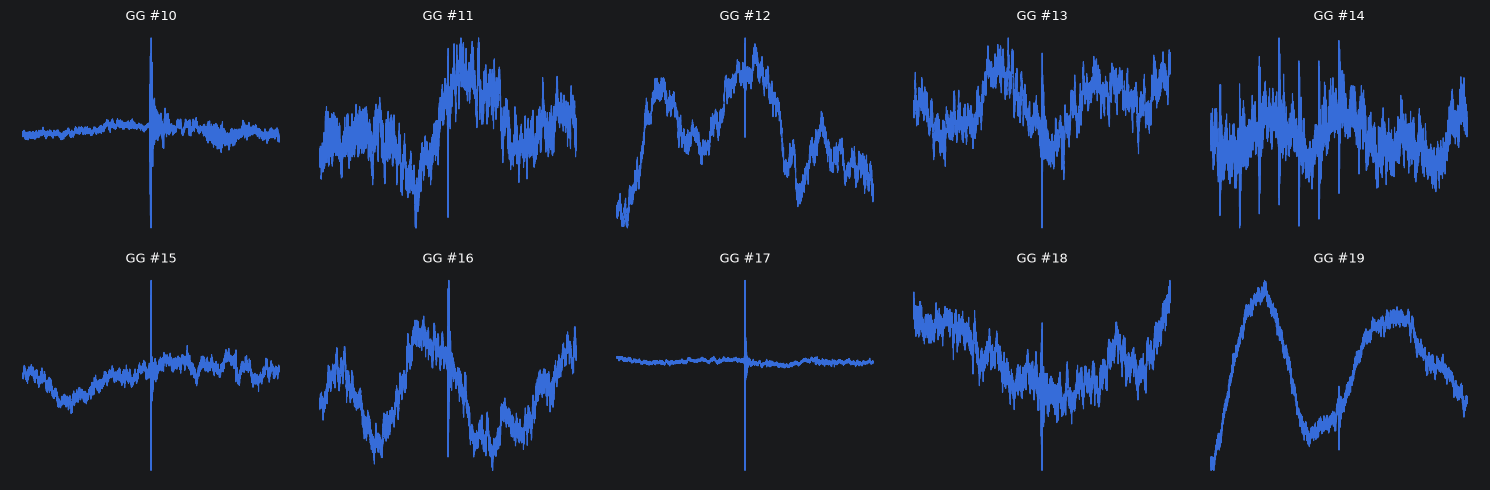

In [12]:
fig, axes = plt.subplots(2, 5, figsize=(15, 5))
for ax, i in zip(axes.flat, range(10, 20)):
    ax.plot(categories['GG'][i], lw=0.8)
    ax.set_title(f'GG #{i}', fontsize=9)
    ax.axis('off')
plt.tight_layout()
plt.show()

### Visualisation des différences entre classes

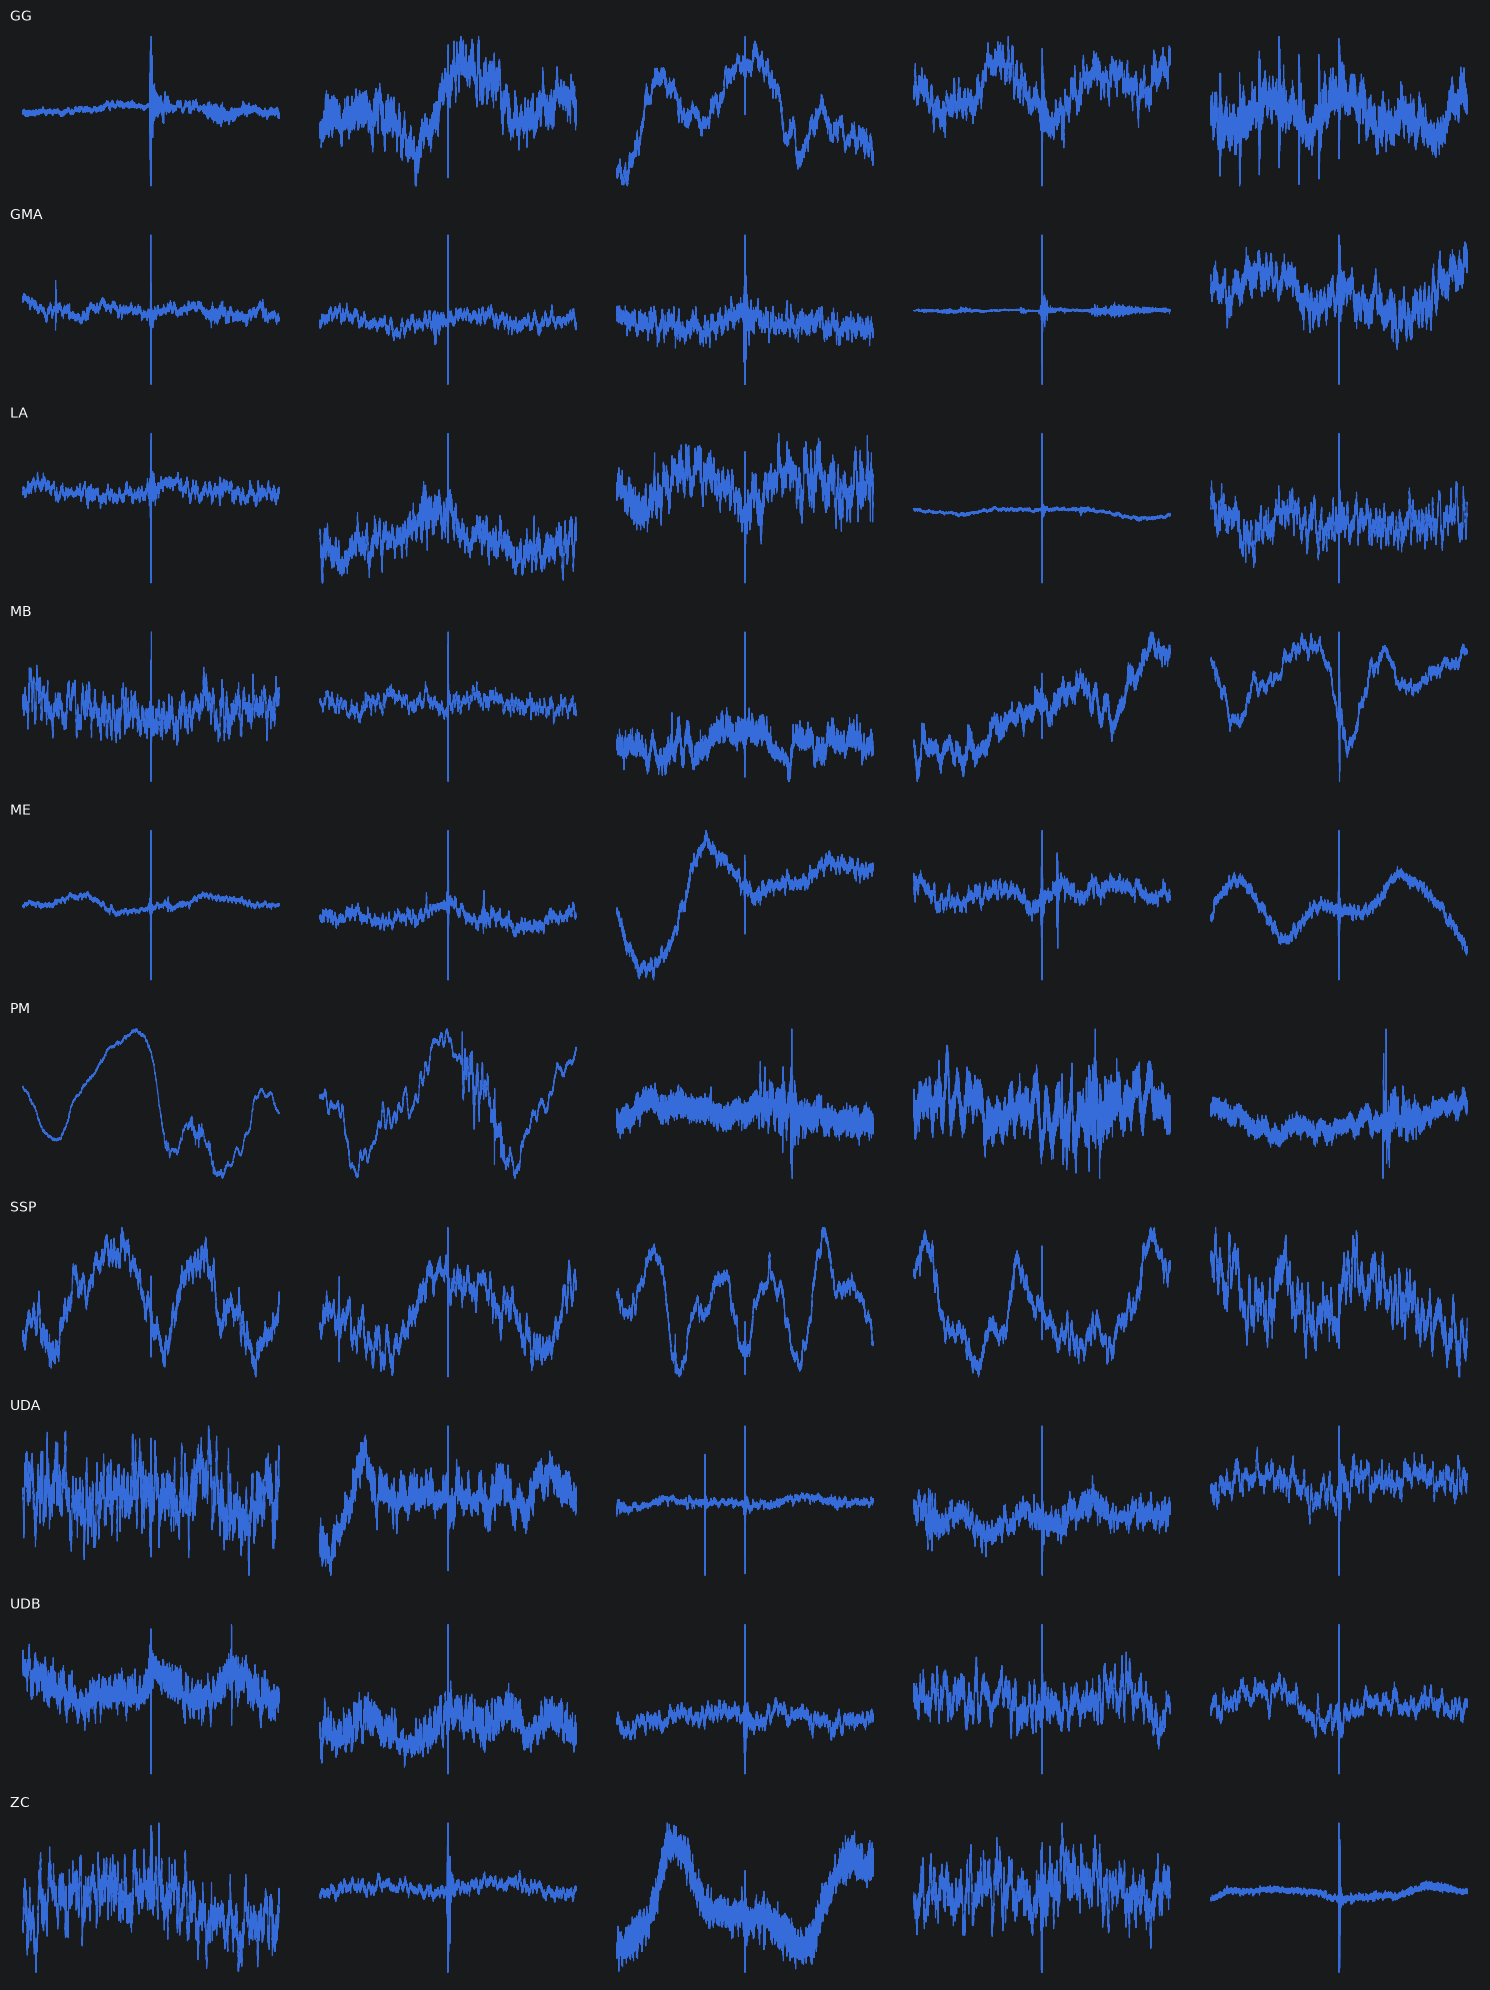

In [13]:
classes = list(categories.keys())
fig, axes = plt.subplots(len(classes), 5, figsize=(15, 2 * len(classes)))
for row, c in enumerate(classes):
    for col in range(5):
        ax = axes[row, col]
        ax.plot(categories[c][10 + col], lw=0.8)
        ax.axis('off')
    axes[row, 0].set_title(c, loc='left', fontsize=10)
plt.tight_layout()
plt.show()

## Preprocessing

### Combinaison d'un passe haut et d'une normalisation

In [10]:
from scipy.signal import butter, sosfiltfilt, hilbert
from scipy.ndimage import uniform_filter1d

fs = 200_000
sos = butter(4, 5_000, btype='highpass', fs=fs, output='sos')   # cut < 5 kHz

def preprocess(X, half=256, batch=2000):
    out = np.empty((len(X), 2*half), dtype=np.float32)
    for i in range(0, len(X), batch):                 # batches: the full array is ~3.7 GB
        xb = sosfiltfilt(sos, X[i:i+batch], axis=1)
        env = uniform_filter1d(np.abs(hilbert(xb, axis=1)), 64, axis=1)  # smoothed envelope
        pk = env[:, half:-half].argmax(1) + half                         # click position
        idx = pk[:, None] + np.arange(-half, half)
        seg = np.take_along_axis(xb, idx, axis=1)
        seg /= np.abs(seg).max(1, keepdims=True) + 1e-9                  # amplitude norm
        out[i:i+batch] = seg
    return out

Xp_train = preprocess(X_train)
Xp_test  = preprocess(X_test)       # apply exactly the same steps to the test set
y_lab = Y_train_df['TARGET'].values

### Visualisation avant / après (pré-traitement)

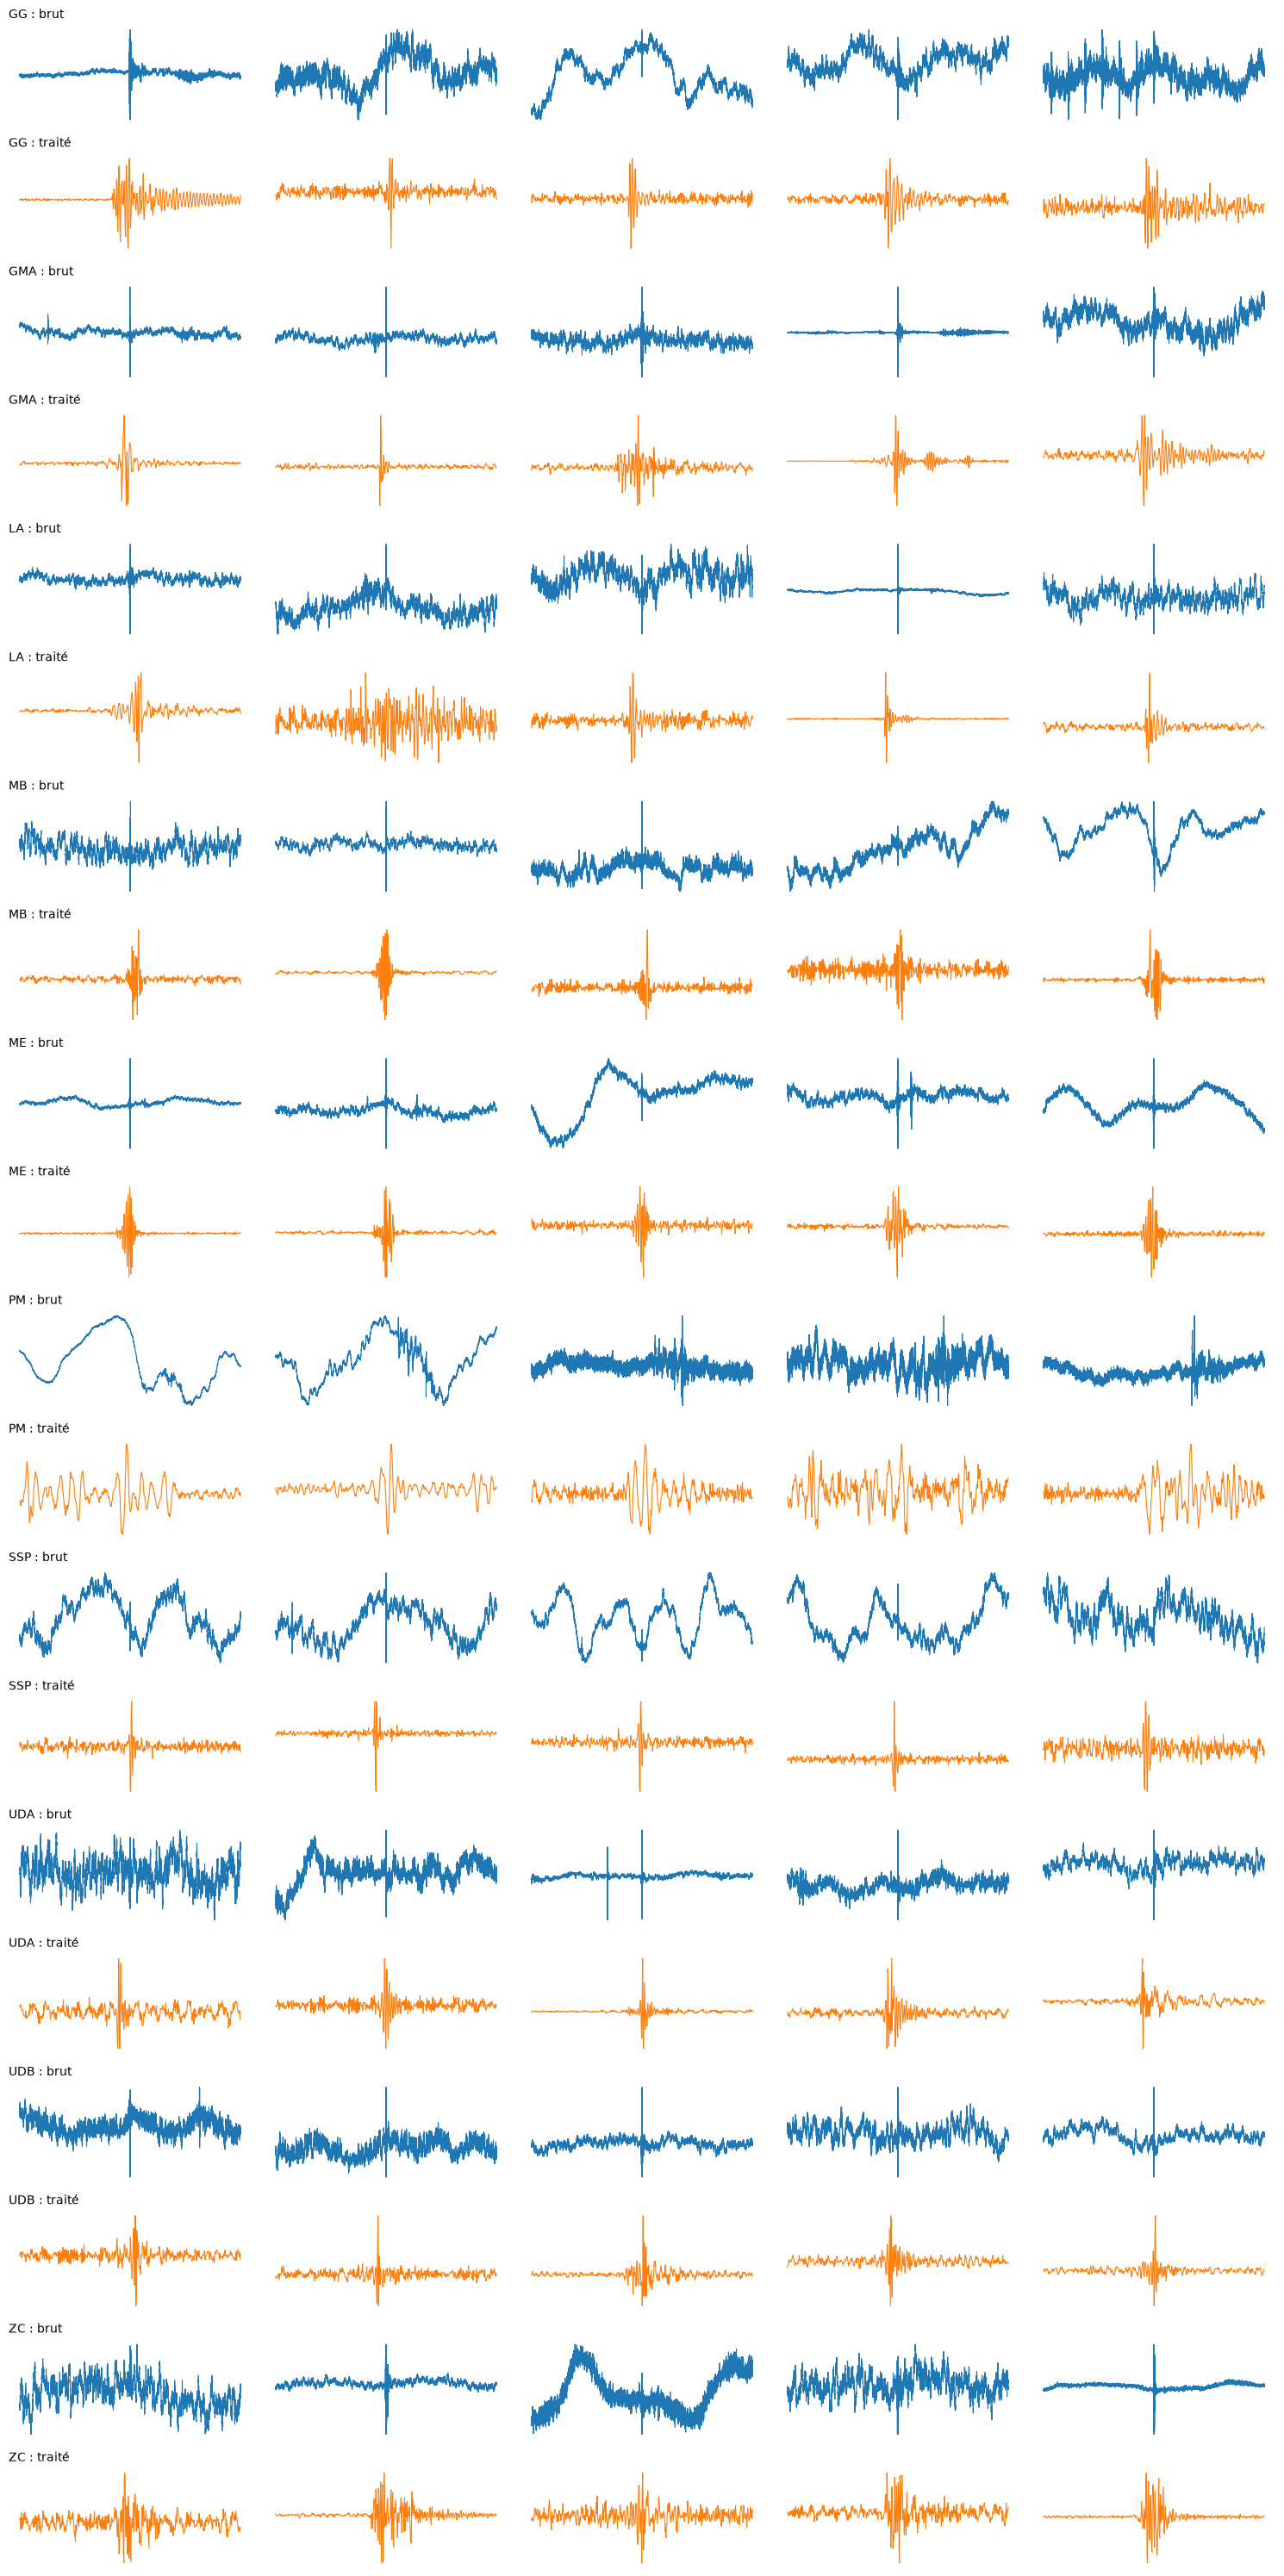

In [13]:
categoriesP = {
    cat: Xp_train[(Y_train_df['TARGET'] == cat).values]
    for cat in sorted(Y_train_df['TARGET'].unique())
}

classes = list(categories.keys())
fig, axes = plt.subplots(len(classes) * 2, 5, figsize=(15, 3 * len(classes)))
for row, c in enumerate(classes):
    for col in range(5):
        ax_brut = axes[2 * row, col]        # ligne paire : signal brut
        ax_trait = axes[2 * row + 1, col]   # ligne impaire : signal traité
        ax_brut.plot(categories[c][10 + col], lw=0.8, color='C0')
        ax_trait.plot(categoriesP[c][10 + col], lw=0.8, color='C1')
        ax_brut.axis('off')
        ax_trait.axis('off')
    axes[2 * row, 0].set_title(f'{c} : brut', loc='left', fontsize=10)
    axes[2 * row + 1, 0].set_title(f'{c} : traité', loc='left', fontsize=10)
plt.tight_layout()
plt.show()

# Modélisation (Ridge, CNN-1D, Gradient Boosting)

## CNN-1D

### Block de CNN

In [14]:
""" x ─ conv1 (c_in → c_out) ─ BN ─ ReLU ─ conv2 (c_out → c_out) ─ BN ─ ReLU ─ maxpool /2 """

class Block(nn.Module):
    def __init__(self, c_in, c_out, k):
        super().__init__()
        self.conv1 = nn.Conv1d(c_in, c_out, k, padding=k//2, bias=False)
        self.bn1 = nn.BatchNorm1d(c_out)
        self.conv2 = nn.Conv1d(c_out, c_out, k, padding=k//2, bias=False)
        self.bn2 = nn.BatchNorm1d(c_out)

    def forward(self, x):
        x = F.relu(self.bn1(self.conv1(x)))
        x = F.relu(self.bn2(self.conv2(x)))
        return F.max_pool1d(x, 2)

### Click-CNN (initialisation)

In [17]:
class ClickCNN(nn.Module):
    def __init__(self, n_classes):
        super().__init__()
        self.features = nn.Sequential(
            Block(1, 32, 9),     # 512 -> 256
            Block(32, 64, 7),    # 256 -> 128
            Block(64, 128, 5),   # 128 -> 64
            Block(128, 128, 3),  # 64 -> 32
            Block(128, 256, 3),  # 32 -> 16
        )
        self.head = nn.Sequential(nn.Dropout(0.3), nn.Linear(2*256, n_classes))

    def forward(self, x):
        x = self.features(x)
        # moyenne + max global : insensible à la position exacte du clic
        x = torch.cat([x.mean(-1), x.amax(-1)], dim=1)
        return self.head(x)

### Click-CNN (entrainement)

In [18]:
def train_cnn():

    Xp = load_preprocessed('train', './DOCC10_train/DOCC10_Xtrain.npy')

    labels = pd.read_csv('./DOCC10_Ytrain.csv', index_col=0)['TARGET'].values
    classes = np.unique(labels)
    y = np.searchsorted(classes, labels)

    tr_idx, va_idx = make_split(y)
    ytr, yva = y[tr_idx], y[va_idx]

    # sans normalisation par signal, on ramène quand même les données à une échelle raisonnable
    sample = np.asarray(Xp[np.sort(np.random.choice(tr_idx, 2000, replace=False))], dtype=np.float32)
    scale = float(sample.std()) if ARGS.no_norm else 1.0
    Xtr = to_gpu(Xp, tr_idx, scale, dev)
    Xva = to_gpu(Xp, va_idx, scale, dev)
    ytr = torch.from_numpy(ytr).to(dev)
    if ARGS.noise_swap > 0:
        assert ARGS.crop == 8192 and ARGS.no_recentre, "l'échange de bruit suppose le signal complet non recentré"
        pos_tr = torch.from_numpy(click_positions(np.load('./DOCC10_train/DOCC10_Xtrain.npy', mmap_mode='r'))[tr_idx]).to(dev)

    model = ClickCNN(len(classes)).to(dev)
    opt = torch.optim.AdamW(model.parameters(), lr=LR, weight_decay=1e-2)
    steps = EPOCHS * ((len(Xtr) + BATCH - 1) // BATCH)
    sched = torch.optim.lr_scheduler.OneCycleLR(opt, max_lr=LR, total_steps=steps)
    print(f'{TAG}{SPLIT_TAG}, {sum(p.numel() for p in model.parameters())/1e3:.0f}k paramètres, {len(Xtr)} train / {len(Xva)} val')

    best_acc = 0
    for epoch in range(EPOCHS):
        model.train()
        t0 = time.time()
        perm = torch.randperm(len(Xtr), device=dev)
        total_loss = 0
        for i in range(0, len(Xtr), BATCH):
            b = perm[i:i+BATCH]
            with torch.autocast('cuda', dtype=torch.bfloat16):
                xb = Xtr[b]
                if ARGS.noise_swap > 0:
                    xb = noise_swap(xb, pos_tr[b], ARGS.noise_swap)
                loss = F.cross_entropy(model(augment(xb)), ytr[b], label_smoothing=0.05)
            opt.zero_grad(set_to_none=True)
            loss.backward()
            opt.step()
            sched.step()
            total_loss += loss.item() * len(b)

        acc = accuracy_score(yva, predict(model, Xva).argmax(1).cpu().numpy())
        if acc > best_acc:
            best_acc = acc
            torch.save(model.state_dict(), f'cnn1d_best_{TAG}{SPLIT_TAG}.pt')
        print(f'epoch {epoch+1:2d}  loss {total_loss/len(Xtr):.4f}  val acc {acc:.4f}  ({time.time()-t0:.0f} s)')

    model.load_state_dict(torch.load(f'cnn1d_best_{TAG}{SPLIT_TAG}.pt'))
    pred = predict(model, Xva).argmax(1).cpu().numpy()
    print(f'\nMeilleure val acc : {best_acc:.4f}\n')
    print(classification_report(yva, pred, target_names=classes, digits=3))
    print(pd.DataFrame(confusion_matrix(yva, pred), index=classes, columns=classes))

In [ ]:
 train_cnn()

crop1024, 576k paramètres, 90496 train / 22624 val
epoch  1  loss 1.1248  val acc 0.8381  (27 s)
epoch  2  loss 0.7749  val acc 0.8607  (8 s)
epoch  3  loss 0.7176  val acc 0.8792  (8 s)
epoch  4  loss 0.6865  val acc 0.8507  (8 s)
epoch  5  loss 0.6697  val acc 0.8763  (8 s)
epoch  6  loss 0.6519  val acc 0.8820  (8 s)
epoch  7  loss 0.6363  val acc 0.8663  (8 s)
epoch  8  loss 0.6202  val acc 0.8924  (8 s)
epoch  9  loss 0.6062  val acc 0.8600  (8 s)
epoch 10  loss 0.5933  val acc 0.8861  (7 s)
epoch 11  loss 0.5861  val acc 0.9124  (7 s)
epoch 12  loss 0.5740  val acc 0.9126  (7 s)


## Gradient Boosting

### Gradient Boosting (entraînement)

In [15]:
def train_gb():

    Fx = gb_load_features('train', './DOCC10_train/DOCC10_Xtrain.npy')

    labels = pd.read_csv('./DOCC10_Ytrain.csv', index_col=0)['TARGET'].values
    classes = np.unique(labels)
    y = np.searchsorted(classes, labels)

    tr_idx, va_idx, te_idx = gb_split(y)
    print(f'gradient boosting, split {GB_ARGS.split}, {Fx.shape[1]} variables, '
          f'{len(tr_idx)} train / {len(va_idx)} val / {len(te_idx)} test')

    t0 = time.time()
    model = HistGradientBoostingClassifier(**GB_PARAMS, random_state=GB_ARGS.seed).fit(Fx[tr_idx], y[tr_idx])
    print(f'{model.n_iter_} itérations ({time.time() - t0:.0f} s)')
    print(f'train acc {accuracy_score(y[tr_idx], model.predict(Fx[tr_idx])):.4f}  '
          f'val acc {accuracy_score(y[va_idx], model.predict(Fx[va_idx])):.4f}')

    pred = model.predict(Fx[te_idx])
    print(f'\nTest acc : {accuracy_score(y[te_idx], pred):.4f}\n')
    print(classification_report(y[te_idx], pred, target_names=classes, digits=3))
    print(pd.DataFrame(confusion_matrix(y[te_idx], pred), index=classes, columns=classes))
    return model

In [16]:
gb_model = train_gb()

gradient boosting, split random, 86 variables, 79184 train / 16968 val / 16968 test
629 itérations (45 s)
train acc 0.9814  val acc 0.8356

Test acc : 0.8361

              precision    recall  f1-score   support

          GG      0.764     0.727     0.745      1697
         GMA      0.829     0.797     0.813      1697
          LA      0.736     0.682     0.708      1697
          MB      0.970     0.976     0.973      1697
          ME      0.901     0.883     0.892      1697
          PM      1.000     0.999     1.000      1697
         SSP      0.876     0.929     0.902      1697
         UDA      0.708     0.747     0.727      1697
         UDB      0.727     0.754     0.740      1696
          ZC      0.848     0.866     0.857      1696

    accuracy                          0.836     16968
   macro avg      0.836     0.836     0.836     16968
weighted avg      0.836     0.836     0.836     16968

       GG   GMA    LA    MB    ME    PM   SSP   UDA   UDB    ZC
GG   1234    58   

### Gradient Boosting (pseudo-sessions)

In [17]:
def eval_gb_pseudo_sessions(n_splits=5):
    Fx = gb_load_features('train', './DOCC10_train/DOCC10_Xtrain.npy')
    labels = pd.read_csv('./DOCC10_Ytrain.csv', index_col=0)['TARGET'].values
    classes = np.unique(labels)
    y = np.searchsorted(classes, labels)

    accs, rappels = [], []
    for tr, te in GroupKFold(n_splits=n_splits).split(Fx, y, groups=gb_pseudo_sessions(y)):
        pred = HistGradientBoostingClassifier(**GB_PARAMS, random_state=GB_ARGS.seed).fit(Fx[tr], y[tr]).predict(Fx[te])
        accs.append(accuracy_score(y[te], pred))
        rappels.append([np.mean(pred[y[te] == k] == k) for k in range(len(classes))])
    print(f'pseudo-sessions : {np.mean(accs):.4f} ± {np.std(accs):.4f}\n')
    print(pd.Series(np.mean(rappels, axis=0), index=classes, name='rappel').round(3))

In [18]:
eval_gb_pseudo_sessions()

pseudo-sessions : 0.8353 ± 0.0011

GG     0.739
GMA    0.806
LA     0.680
MB     0.975
ME     0.892
PM     0.998
SSP    0.924
UDA    0.744
UDB    0.739
ZC     0.856
Name: rappel, dtype: float64


# Baseline (regression ridge)

In [ ]:
# cross validate the ridge parameter alpha
alphas = 10.**(-np.arange(-5,5))
best_acc = 0
best_alpha = -1

for alpha in alphas:
    t0 = time.time()
    reg = make_pipeline(StandardScaler(), Ridge(alpha=alpha))
    y_pred = cross_val_predict(reg, X=X, y=y, cv=4)
    acc = accuracy_score(np.argmax(y, axis=1), np.argmax(y_pred, axis=1))
    if acc > best_acc:
        best_acc, best_alpha = acc, alpha
    t = (time.time() - t0) / 60
    print(f'alpha={alpha} acc={acc}, t = {t:.1f} min')

In [ ]:
# fit regressor on the whole train db
reg = make_pipeline(StandardScaler(), Ridge(alpha=best_alpha))
reg.fit(X, y)

In [ ]:
# save predictions to csv for submission
y_test_pred = reg.predict(X_test.astype('float32'))
y_test_pred = (y_test_pred == y_test_pred.max(axis=1, keepdims=True)).astype(float)
y_test_pred = enc.inverse_transform(y_test_pred)
Y_test_pred_df = pd.DataFrame(data=y_test_pred, index=np.arange(y_test_pred.shape[0]), columns=['TARGET'])
Y_test_pred_df.to_csv('./DOCC10_Ytest_pred_linear.csv', index_label='ID')